# Day 10 — Probability | Internship Task 10
**Date:** 23 November 2026  
**Goal:** 15 solved problems in companion PDF; implement 5 in Python and visualize distributions.

The notebook uses only Python standard library, NumPy, and Matplotlib. All calculations use explicit assumptions.

## Concepts and formulas
- Classical probability: $P(A)=\frac{\text{favorable}}{\text{total}}$
- Conditional: $P(A|B)=P(A\cap B)/P(B)$
- Independent: $P(A\cap B)=P(A)P(B)$
- Bayes: $P(A|B)=P(B|A)P(A)/P(B)$
- Binomial: $P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$
- Normal: $Z=(X-\mu)/\sigma$.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
print("NumPy version:", np.__version__)

NumPy version: 2.3.5


## Implementation 1 — Basic probability (Problem 2)
For a fair six-sided die, the even faces are 2, 4, and 6.

In [2]:
faces = list(range(1, 7))
even = [x for x in faces if x % 2 == 0]
p_even = len(even) / len(faces)
print(f"Even outcomes: {even}; P(even) = {p_even:.6f}")
assert math.isclose(p_even, 0.5)

Even outcomes: [2, 4, 6]; P(even) = 0.500000


## Implementation 2 — Dependent draws (Problem 8)
Five red and three blue balls; two draws **without replacement**.

In [3]:
p_both_red = (5/8) * (4/7)
print(f"P(two red without replacement) = {p_both_red:.6f}")
assert math.isclose(p_both_red, 5/14)

P(two red without replacement) = 0.357143


## Implementation 3 — Bayes theorem (Problem 11)
Hypothetical screening example: prevalence 1%, sensitivity 90%, false positive rate 5%.

In [4]:
prevalence, sensitivity, false_positive = 0.01, 0.90, 0.05
p_positive = sensitivity*prevalence + false_positive*(1-prevalence)
p_disease_given_positive = sensitivity*prevalence/p_positive
print(f"P(positive) = {p_positive:.6f}")
print(f"P(disease | positive) = {p_disease_given_positive:.6f}")
assert math.isclose(p_disease_given_positive, 0.009/0.0585)

P(positive) = 0.058500
P(disease | positive) = 0.153846


## Implementation 4 — Binomial distribution (Problem 13)
Exactly two heads in four fair tosses.

In [5]:
n, p, k = 4, 0.5, 2
p_two_heads = math.comb(n,k)*(p**k)*((1-p)**(n-k))
print(f"P(exactly 2 heads in 4 tosses) = {p_two_heads:.6f}")
assert math.isclose(p_two_heads, 0.375)

P(exactly 2 heads in 4 tosses) = 0.375000


## Implementation 5 — Normal distribution (Problem 15)
For $X\sim N(100,10^2)$, calculate $P(X<110)$ using the error function.

In [6]:
mu, sigma, cutoff = 100, 10, 110
z = (cutoff-mu)/sigma
p_below = 0.5*(1+math.erf(z/math.sqrt(2)))
print(f"Z-score = {z:.2f}; P(X < 110) = {p_below:.6f}")
assert math.isclose(p_below, 0.8413447460685429)

Z-score = 1.00; P(X < 110) = 0.841345


## Visualization 1 — Fair die probability

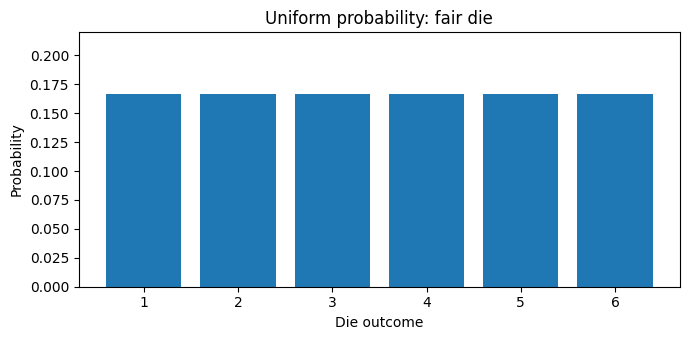

In [7]:
fig, ax = plt.subplots(figsize=(7,3.5))
ax.bar([str(x) for x in faces], [1/6]*6)
ax.set(xlabel="Die outcome", ylabel="Probability", title="Uniform probability: fair die", ylim=(0,0.22))
plt.tight_layout(); plt.savefig("Day10_Die_Probability.png", dpi=160); plt.show()

## Visualization 2 — Binomial distribution for four tosses

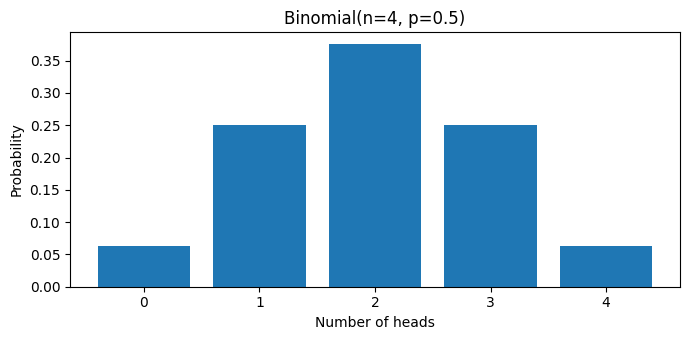

Sum of binomial probabilities: 1.0


In [8]:
xs = np.arange(5)
ys = [math.comb(4,int(x))*0.5**4 for x in xs]
fig, ax = plt.subplots(figsize=(7,3.5))
ax.bar(xs,ys); ax.set(xlabel="Number of heads",ylabel="Probability",title="Binomial(n=4, p=0.5)",xticks=xs)
plt.tight_layout(); plt.savefig("Day10_Binomial_Distribution.png",dpi=160); plt.show()
print("Sum of binomial probabilities:",sum(ys))

## Visualization 3 — Normal distribution and shaded probability

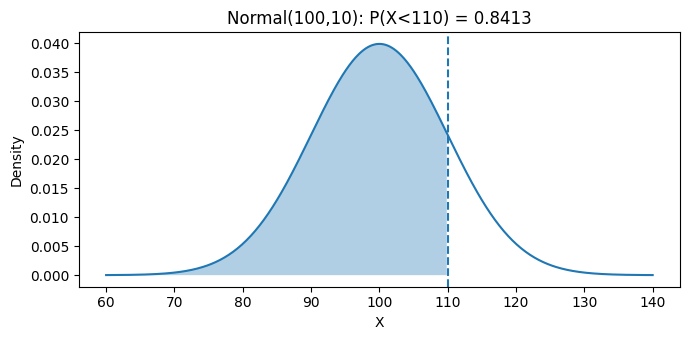

In [9]:
x=np.linspace(60,140,500)
y=np.exp(-0.5*((x-mu)/sigma)**2)/(sigma*np.sqrt(2*np.pi))
fig, ax=plt.subplots(figsize=(7,3.5))
ax.plot(x,y); ax.fill_between(x,y,where=x<cutoff,alpha=0.35)
ax.axvline(cutoff,linestyle="--"); ax.set(xlabel="X",ylabel="Density",title=f"Normal(100,10): P(X<110) = {p_below:.4f}")
plt.tight_layout();plt.savefig("Day10_Normal_Distribution.png",dpi=160);plt.show()

## Summary and business interpretation
1. Probability quantifies uncertainty.
2. Conditional probability updates an estimate using additional information.
3. Independent events multiply directly; without-replacement draws require conditional probabilities.
4. Bayes theorem can update defect-risk or screening probabilities.
5. Binomial models counts of successes; normal models continuous measurements.

**Proof:** run all cells in VS Code/Jupyter, then capture screenshots of the five numerical outputs and three charts.